# Does a LoRA update miss the subcomponents on the read side, the write side, or both?

*E14, 2026-10-20. Plan: `reports/2026-10-20_plan_lora-split.md`. Record: `reports/2026-10-20_analysis_lora-split.md`.*

## The answer

The LoRA misses on the read side and the fine-tune does not. On the write side the two updates are alike: neither is more aligned with what the subcomponents write than a random update is, until the fine-tune's thousandth step. Neither update rescales the existing subcomponents; that share stays below seven percent. Applied as the adjoint split, the ten-step fine-tune keeps most of its behaviour and the decomposition stays as faithful as the original model's. The least-squares split of the same update reads five times worse. The behaviour kept fades with longer training.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

R = Path('../experiments/lora_split/results')
F = Path('../experiments/lora_split/figures')
out = json.loads((R / 'lora_split.json').read_text())
T, part2, score = out['table'], out['part2'], out['score']
NAME = {'ft': 'full fine-tune', 'lora24': 'rank-8 LoRA, 24 matrices'}


def pooled(u, s):
    rec = T[u][s]
    return rec['pooled_ns'] or rec['pooled_all']


def side(p, which):
    a, b = ('in_in', 'out_in') if which == 'read' else ('in_in', 'in_out')
    return (p[a] + p[b]) / (p['null_' + a] + p['null_' + b])

## What we were trying to test

The question since the project's first week: take a finished LoRA update, split it over the subcomponents, and see how much of it the subcomponents cannot take. Earlier runs measured one number, the share of the update outside both the read and the write directions of the subcomponents. They found that a LoRA sits outside about as much as noise does while a fine-tune sits well inside. One number cannot say which side the LoRA misses on, and the two update types had never been measured on one card at the same steps. This run does both.

The model is the released VPD decomposition of the 67M model. Each of the 24 decomposed matrices is $W = U V^\top + \Delta$, where alive subcomponent $c$ reads its input along $v_c$ and writes its output along $u_c$. The importance function Γ and the remainder Δ are frozen throughout. The task is the paper's emoticon one, where the model learns to answer a trigger with the letter o.

Three kinds of update, all on that task. The full fine-tune of the 24 matrices with Adam at one seed, run once here, with its weight change $\delta W$ kept at nine steps from 1 to 1000. The rank-8 LoRA on all 24 matrices from the plateau run, read back from its saved factors at the same nine steps; nothing is retrained. Five LoRAs on the paper's single matrix, ranks 1, 4, 8 and 32 plus a second seed at rank 8, at steps 10, 30 and 100, also from saved factors.

For every update and matrix, the update's effect on the real inputs is cut into four blocks that sum to one. The effect is $\|\delta W\,\Sigma^{1/2}\|^2$, with Σ the second moment of that matrix's inputs over Pile windows. On the write side: the part of the output inside the span of the $u_c$, against the rest. On the read side: the part of the input predictable from what the subcomponents read, $a_1 = E[a \mid V^\top a]$, against the uncorrelated remainder $a_2$. "Inside both" is energy a first-order move of the subcomponents could produce; "outside both" is what no such move can produce on these inputs. Each block has an exact reference: its value for a random update of the same size per matrix. A block divided by its reference reads 1 when the update is no more aligned with the subcomponents than noise is. Blocks are pooled by energy over the 20 matrices whose subcomponents do not already span a whole side. On the other four MLP matrices the outside block is zero for every update.

Two more numbers per update. The rescaling share is the energy a weighted least-squares fit $\delta W \approx \sum_c \alpha_c u_c v_c^\top$ explains, against two random draws; it is the strictest reading of "the update strengthens existing subcomponents". For each of the two splits below, the count of subcomponents that carry half the split's energy says how concentrated it is.

Part 2 puts three states of each update at steps 10, 100 and 1000 through the standing checks. Do-nothing leaves $\delta W$ in Δ. The least-squares split is the least-norm per-subcomponent move $(dU, dV)$ with $dU V^\top + U dV^\top \approx \delta W$, with the remainder in Δ. The adjoint split moves each subcomponent by $dU = \delta W V$ and $dV = \delta W^\top U$ with no solve and Δ untouched. Its weight change is $U U^\top \delta W + \delta W V V^\top$, which is not $\delta W$, so each matrix's move is scaled by the least-squares scalar $c$ and the state describes a slightly different model. Three checks. VPD's adversarial faithfulness check on Pile, as a ratio to the original model, with the original model's own spread under three adversary seeds as the floor. The route split at the trigger. The held-out probability of the target. The standing algebraic outside share is kept as one extra column so the earlier runs stay comparable, with the gate that it reproduces the plateau run's three numbers exactly. It did.

## What we expected, and why

- **The LoRA at its random reference on both sides at every step.** In the plateau run its read factor stayed within a degree of its random start for a thousand steps, and its outside share sat at the reference throughout. That leaves little room for either side to be inside.
- **The fine-tune inside on both sides from step 10 on**, with its outside block at most 0.7 of the reference. Its read side is shaped by the data, and the matched-matrix run's algebraic number read 0.27 against 0.53.
- **No rescaling**: the share at most three times its random reference for both updates at every step, since the first-week run read 0.06 percent against 0.035.
- **Rank is not the axis**: the one-matrix LoRAs' outside block between 0.8 and 1.2 of its reference at every rank and step, as the algebraic share had read.
- **The adjoint state**, a first reading with no threshold: its held-out probability of the target should track the share of the update it reproduces.
- **On one card**, the split LoRA's adversarial ratio inside the floor at all three steps and the split fine-tune's at least 2 at step 10.

## What we observed

### 1. Which side does each update miss?

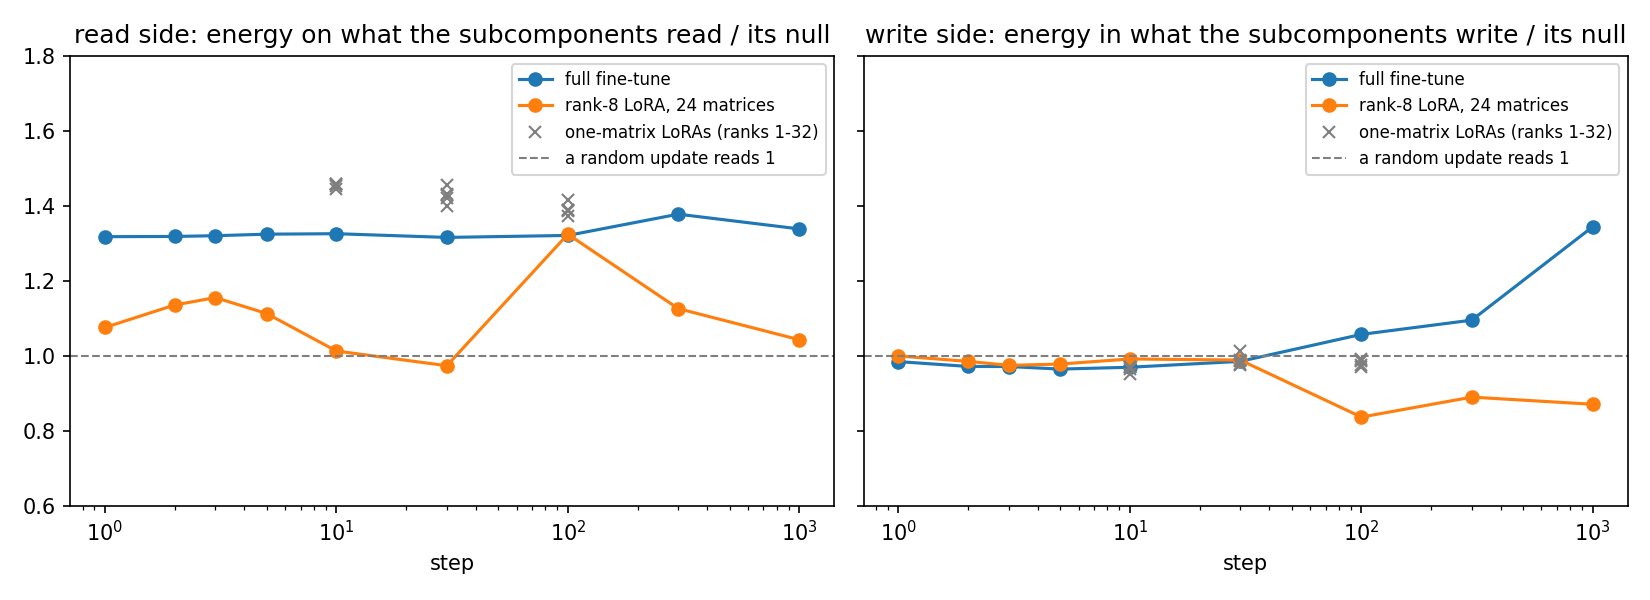

In [2]:
display(Image(F / 'sides.png', width=1100))

**Reading it.** The LoRA misses on the read side and the fine-tune does not; on the write side both updates sit at the random reference. The left panel is the share of each update's energy on the inputs the subcomponents read, divided by what a random update would have. The fine-tune reads 1.32 at its first step and stays there to step 1000. The LoRA reads between 1.0 and 1.15 at every step but one, step 100, where it reads 1.32 and then falls back. The right panel is the write side: both updates read between 0.96 and 1.0 through step 30. The fine-tune's write side starts moving inside only after step 100 and reaches 1.34 at step 1000, while the LoRA's drops to 0.84 to 0.89. The grey crosses are the one-matrix LoRAs: 1.4 on the read side at every rank, about 1.0 on the write side. The fine-tune reads 1.45 on that same matrix, so that is the matrix speaking, not the LoRA. One caveat: the write-side reference is small on the attention query and key matrices, 2 to 16 percent of the output directions, so moving inside there means landing in a thin subspace. The fine-tune's energy sits mostly on the MLP input matrices, and its write side is at or below the reference there too.

In [3]:
rows = []
for u in ('ft', 'lora24'):
    for s in ('1', '10', '100', '1000'):
        p = pooled(u, s)
        rows.append((NAME[u], int(s), round(side(p, 'read'), 2), round(side(p, 'write'), 2), round(p['out_out'] / p['null_out_out'], 2)))
pd.DataFrame(rows, columns=['update', 'step', 'read side / reference', 'write side / reference', 'outside both / reference'])

,update,step,read side / reference,write side / reference,outside both / reference
0,full fine-tune,1,1.32,0.98,0.18
1,full fine-tune,10,1.33,0.97,0.22
2,full fine-tune,100,1.32,1.06,0.33
3,full fine-tune,1000,1.34,1.34,0.41
4,"rank-8 LoRA, 24 matrices",1,1.08,1.00,0.84
5,"rank-8 LoRA, 24 matrices",10,1.01,0.99,0.98
6,"rank-8 LoRA, 24 matrices",100,1.32,0.84,0.54
7,"rank-8 LoRA, 24 matrices",1000,1.04,0.87,0.95


### 2. How far outside is each update, and does rescaling explain any of it?

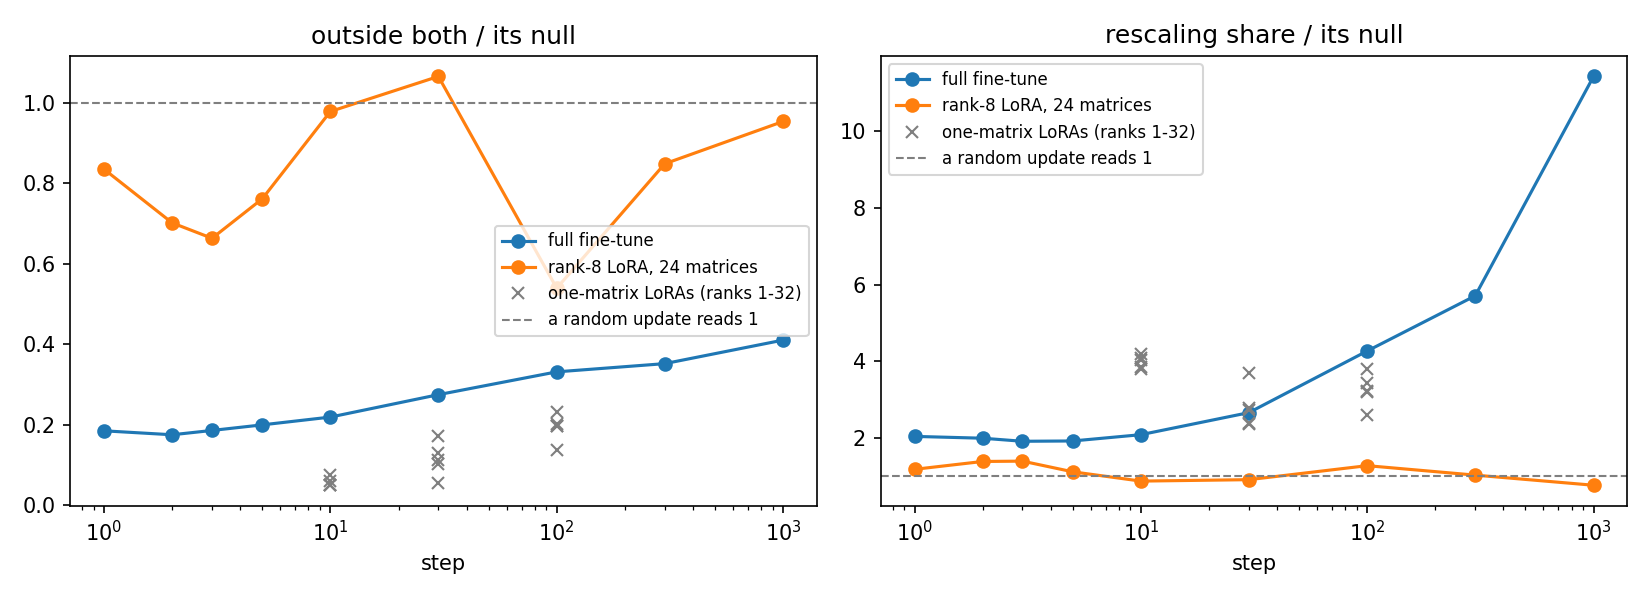

In [4]:
display(Image(F / 'outside.png', width=1100))

**Reading it.** The fine-tune sits inside and drifts outward as training goes on; the LoRA sits at noise throughout; rescaling explains little of either, but a growing part of the fine-tune. The left panel is the outside-both block divided by its reference. The fine-tune reads 0.18 at step 1 and 0.41 at step 1000, rising at every checkpoint. The LoRA reads between 0.54 and 1.07 with no trend, the same verdict the plateau run reached through its algebraic number, which this run reproduces to three digits. The right panel is the rescaling share against its random reference. The LoRA's stays between 0.6 and 1.8 times random, which is noise. The fine-tune's is twice random for its first 30 steps, then climbs to 9.6 times by step 1000; in absolute terms that is 2 percent of its energy rising to 7. So strengthening the existing subcomponents is a small and growing part of a fine-tune and no part of a LoRA. The first-week audit saw the same climb on a different fine-tune, and this run repeats it.

### 3. Does the rank of a one-matrix LoRA matter?

The one-matrix LoRAs are the grey crosses in the two figures above; the table has their outside block.

In [5]:
rows = []
for u in ('site_r1_s0', 'site_r4_s0', 'site_r8_s0', 'site_r32_s0', 'site_r8_s1'):
    for s in ('10', '100'):
        p = T[u][s]['pooled_all']
        rows.append((u[5:].replace('_s', ', seed ').replace('r', 'rank '), int(s), round(p['out_out'] / p['null_out_out'], 2),
                     round(p['alg_omega_act'] / p['alg_null_act'], 2), round(side(p, 'read'), 2)))
pd.DataFrame(rows, columns=['LoRA', 'step', 'outside both / reference', 'algebraic share / reference', 'read side / reference'])

,LoRA,step,outside both / reference,algebraic share / reference,read side / reference
0,"rank 1, seed 0",10,0.06,0.95,1.45
1,"rank 1, seed 0",100,0.14,0.80,1.42
2,"rank 4, seed 0",10,0.05,1.02,1.46
3,"rank 4, seed 0",100,0.20,0.76,1.39
4,"rank 8, seed 0",10,0.05,0.98,1.46
5,"rank 8, seed 0",100,0.20,0.72,1.39
6,"rank 32, seed 0",10,0.08,0.91,1.45
7,"rank 32, seed 0",100,0.23,0.73,1.37
8,"rank 8, seed 1",10,0.05,0.99,1.46
9,"rank 8, seed 1",100,0.20,0.68,1.39


**Reading it.** Rank does not matter, but the filed band was wrong for this measurement. At every rank from 1 to 32 and both seeds, the outside block sits within 0.03 of the others at the same step. It reads 0.05 to 0.08 of its reference at step 10 and 0.14 to 0.23 at step 100. The band filed was 0.8 to 1.2, taken from the algebraic share, which reads 0.30 to 0.43 against 0.42 here, as it did in the one-matrix run. The input-weighted blocks say something different about this matrix: its inputs are 67 percent predictable from what its subcomponents read, and every update's read direction sits 98 percent in that part. The fine-tune and the 24-matrix LoRA read the same on this matrix. So the prediction misses on its threshold while the claim it was written for holds.

### 4. Which state survives the adversary and still does the behaviour?

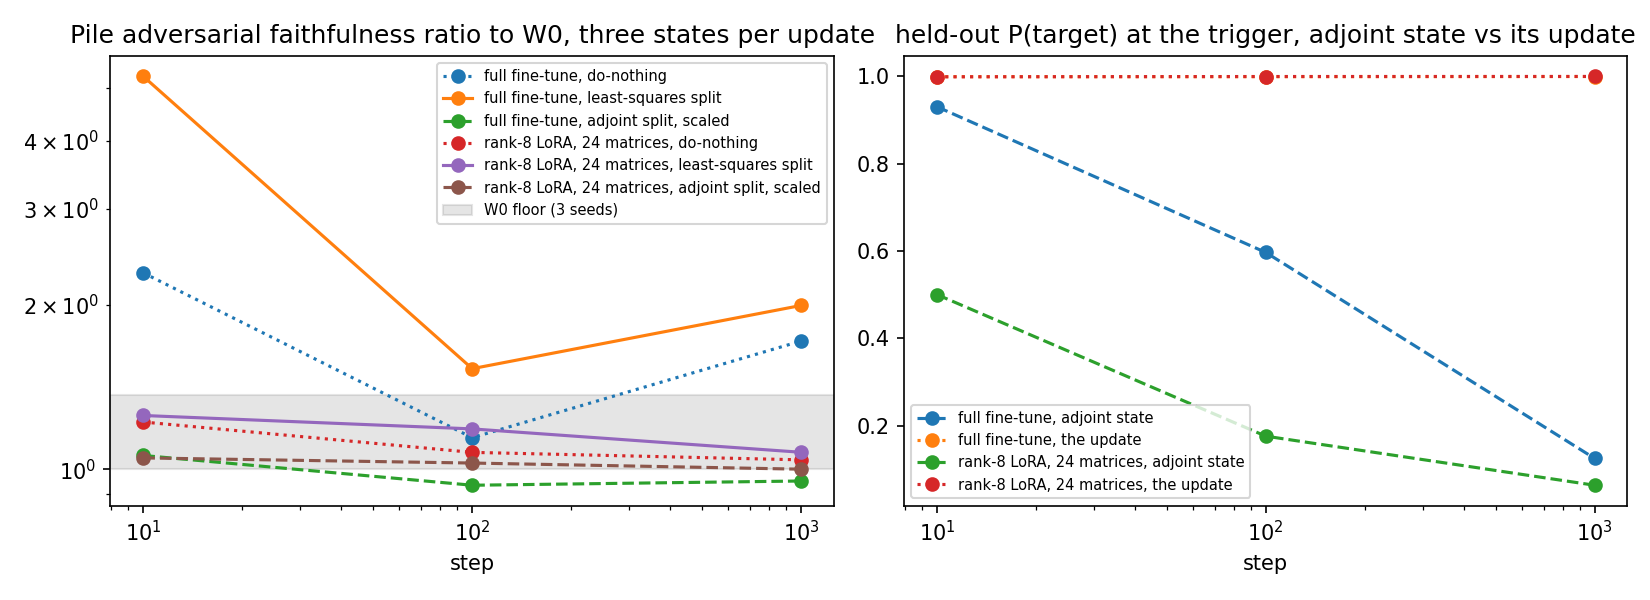

In [6]:
display(Image(F / 'pile.png', width=1100))

**Reading it.** The scaled adjoint state keeps the decomposition at the floor for both updates at every step, and at step 10 the fine-tune's keeps 93 percent of the behaviour. The left panel is each state's adversarial faithfulness ratio to the original model, with the floor as the grey band. The split fine-tune reads 5.2 at step 10, repeating the 5.4 read on another card, and stays above the floor at the later steps. Its do-nothing is above the floor at steps 10 and 1000. The split LoRA reads 1.25, 1.19 and 1.07, inside the floor at every step and within 0.03 of the plateau run, and its do-nothing is at the floor too. The adjoint states read 0.93 to 1.06, all at the floor. That is expected rather than a result: the adjoint moves the subcomponents only along directions they already read and write, and leaves Δ untouched to one part in a million. The right panel is the held-out probability of the target. The adjoint state of the step-10 fine-tune reads 0.93 where the update reads 0.999. It falls to 0.60 at step 100 and 0.12 at step 1000. The LoRA's reads 0.50 at step 10 and 0.06 at step 1000. Both track the share of the update's energy the scaled adjoint reproduces: 0.58 falling to 0.31 for the fine-tune, 0.23 falling to 0.11 for the LoRA. The caveat is that this state is a different model from the fine-tuned one. The Pile checks are blind to the behaviour, so the probability of the target is the only number here with power over it.

In [7]:
rows = []
for u in ('ft', 'lora24'):
    for s in ('10', '100', '1000'):
        for arm, name in (('nothing', 'do-nothing'), ('lift', 'least-squares split'), ('adjoint', 'adjoint split, scaled')):
            a = part2[u][s][arm]
            rows.append((NAME[u], int(s), name, round(a['pile']['pgd_kl'], 2), round(a['routes']['shares']['e_delta'], 2),
                         round(a['routes']['p_cells']['T1'], 2)))
pd.DataFrame(rows, columns=['update', 'step', 'state', 'adversarial ratio', 'share of the gain left in Δ', 'P(target)'])

,update,step,state,adversarial ratio,share of the gain left in Δ,P(target)
0,full fine-tune,10,do-nothing,2.29,1.00,1.00
1,full fine-tune,10,least-squares split,5.24,0.09,1.00
2,full fine-tune,10,"adjoint split, scaled",1.06,0.01,0.93
3,full fine-tune,100,do-nothing,1.14,1.00,1.00
4,full fine-tune,100,least-squares split,1.53,0.16,1.00
5,full fine-tune,100,"adjoint split, scaled",0.93,0.02,0.60
6,full fine-tune,1000,do-nothing,1.72,1.00,1.00
7,full fine-tune,1000,least-squares split,2.00,0.26,1.00
8,full fine-tune,1000,"adjoint split, scaled",0.95,0.02,0.12
9,"rank-8 LoRA, 24 matrices",10,do-nothing,1.22,1.00,1.00


## What we learned

The fine-tune's advantage over the LoRA in expressibility is entirely on the read side. The read side of a gradient update is the data, so the fine-tune reads what the subcomponents read because both are shaped by the same inputs. The LoRA's read factor starts random and barely moves, so it does not. The subcomponents' write directions predict where neither update writes for the first 300 steps, so the "inside" that earlier runs reported for the fine-tune was never about the output side. Longer training does not make an update easier: the fine-tune drifts outward and its rescaling share grows, so the next phase's step sweep must include late steps. The adjoint split applied as a state is the first map in this project that keeps both the behaviour and the adversarial floor for a fine-tune with Δ untouched. It keeps 93 percent of the behaviour at step 10. It does so by describing a different model that carries 58 percent of the update's energy, and what it keeps fades to 12 percent of the behaviour by step 1000. Whether a map that keeps most of the behaviour, rather than all of the update, meets the weak version in `GOALS.md` is the user's decision. The project has no threshold for it.

## How compelling is the evidence

One task, one fine-tune seed and one LoRA seed on the 24 matrices; two seeds at rank 8 on the single matrix. The four blocks have an exact reference, so an "at the reference" reading needs no draws; the rescaling reference is the mean of two draws. The Pile checks cannot see the trained behaviour; the probability of the target is held out on 73 windows and is the only number with power over it. Faithfulness ratios come from one card, an RTX A5000 with a floor of 0.12, and are not comparable across cards. Still, the LoRA states reproduce the L40S run within 0.03, and the split fine-tune reproduces the L40's 5.4 as 5.2. The per-subcomponent updates of both splits were written on the pod and deleted with it, so only their concentration counts survive.

## Surprises

**Something unexpected happened that I cannot explain.** The fine-tune's write side was predicted to be inside, at least 1.3 times its reference at step 10, and read 0.97. The fine-tune writes into the subcomponents' output directions no more than a random update does until after step 100. The read side carries all of its alignment. The write-side spans are thin on the query and key matrices, but the fine-tune's energy sits on the MLP input matrices, where it reads 0.76 to 0.91 on the write side, below the reference. Why a gradient's output directions avoid the subcomponents' output directions is not something this run can say.

Three threshold misses. The fine-tune's rescaling share was predicted to stay under three times random and reads 3.4 at step 100 and 9.6 at step 1000. The first-week audit saw the same climb on another fine-tune, and the log lists it as unexplained; it is now reproduced. The one-matrix LoRAs' outside block was predicted between 0.8 and 1.2 of its reference and reads 0.05 to 0.23. The band was taken from the algebraic share, which this run reproduces; the input-weighted block reads differently on that matrix. The LoRA's read side was predicted under 1.2 at every step and reads 1.32 at one step of nine.

Not a filed prediction, but the run's most useful reading: the adjoint state of the ten-step fine-tune keeps 93 percent of the behaviour at the faithfulness floor.

## What next

- **Recover the per-subcomponent updates.** Rerun the split-table stage on the cluster, about 15 minutes with nothing else changed, and keep the pieces on NFS. Without them the concentration counts cannot be looked at.
- **The adjoint state as a candidate map.** Its off-target damage, a second seed, and the key → value tasks, where the model lacks the association. If the step-10 adjoint state keeps the behaviour at the floor on the cipher too, it is the map to carry to the larger model. If it does so only on emoticon, it reproduces a re-weighting the model could already do.
- **Where does the fine-tune write?** Its output directions against the span of every subcomponent, dead ones included, and against the write directions of the subcomponents Γ switches on at the trigger. If the dead subcomponents' span takes it, the decomposition's choice of which subcomponents to keep alive is what the update misses. Through the design check first.

## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| G1 | the saved factors reproduce the plateau run | algebraic outside share within 0.003 of E9 at steps 10, 100, 1000 | 0.574, 0.552, 0.707, exact | pass |
| G2 | the split state is the update at the trigger | P(target) equal to 1e-3, route shares sum to 1 | differences below 1e-5 | pass |
| P1 | the LoRA is at its reference on both sides | read side ≤ 1.2 and write side ≤ 1.3 at every step | read 0.97 to 1.16 at eight steps, 1.32 at step 100; write 0.84 to 1.00 | miss at one step |
| P2 | the fine-tune is inside on both sides | outside both ≤ 0.7 from step 10; read ≥ 1.3 and write ≥ 1.3 at step 10 | outside 0.22 to 0.41; read 1.33; write 0.97 | miss, reversed on the write side |
| P3 | nothing is rescaled | rescaling ≤ 3 × random for both updates at every step, pooled over 24 | LoRA 0.6 to 1.8; fine-tune 2.0 to 2.3 to step 30, 3.4 at 100, 5.2 at 300, 9.6 at 1000 | miss for the fine-tune from step 100 |
| P4 | rank is not the axis | one-matrix outside both in [0.8, 1.2] at every rank and step | 0.05 to 0.23, within 0.03 across ranks at a step | miss on the band; rank-independence holds |
| P5 | adjoint state behaviour tracks its reproduced share | reported | P(target) 0.93, 0.60, 0.12 for R 0.58, 0.42, 0.31; LoRA 0.50, 0.18, 0.06 for 0.23, 0.12, 0.11 | reported, monotone |
| P6 | one card: split LoRA at the floor, split fine-tune fragile | LoRA ≤ 1.37 at 10, 100, 1000; fine-tune ≥ 2 at step 10 | 1.25, 1.19, 1.07; 5.24 | pass |

## Not run

- The per-subcomponent updates of both splits: written to the pod's disk and deleted when it was terminated; the concentration counts in the results file are all that survives.
- The adjoint state's off-target KL, the unscaled adjoint state, and the adjoint state on any other task or seed.
- E8's factors, which share E9's recipe and seed. A second fine-tune seed. The per-step split.
- The cluster: the smoke job queued behind another user's array for 15 minutes and was cancelled; both runs went to RunPod.

## Provenance

Results `experiments/lora_split/results/lora_split.json`, sha256 7dac2efd…; smoke `lora_split_smoke.json`; logs `results/large/{full,pod_scored,pod_smoke}.log`. RunPod secure cloud, RTX A5000 24 GB, smoke 13 min and scored 85 min, $0.73. Predictions `results/predictions.json`, filed 2026-10-20 15:08 before the run.